# Naive Bayes (Breast Cancer Wisconsin)

## Langkah 1 - Import library

In [1]:
# Fitrya Irfan_202431073
# Langkah 1: import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Langkah 2 - Baca dataset dan tampilkan datanya (head)

In [2]:
# Fitrya Irfan_202431073
# Langkah 2: baca dataset dan tampilkan 5 data teratas
df = pd.read_csv("data.csv")
print(df.head())
print("Ukuran dataset (baris x kolom):", df.shape)


         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

## Langkah 3 - Info dan deskripsi statistik

In [3]:
# Fitrya Irfan_202431073
# Langkah 3: informasi data dan deskripsi statistik
df.info()
print(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

## Langkah 4 - Fitur numerik

In [4]:
# Fitrya Irfan_202431073
# Langkah 4: pisahkan fitur numerik
# Kolom 'id' hanya nomor pasien dan 'Unnamed: 32' kolom kosong akibat koma di akhir header,
# keduanya bukan fitur sehingga dibuang dulu.
df = df.drop(columns=["id", "Unnamed: 32"])

fitur_numerik = df.select_dtypes(include="number").columns.tolist()
print("Jumlah fitur numerik:", len(fitur_numerik))
print(fitur_numerik)


Jumlah fitur numerik: 30
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## Langkah 5 - Fitur kategorikal

In [5]:
# Fitrya Irfan_202431073
# Langkah 5: pisahkan fitur kategorikal
fitur_kategorikal = df.select_dtypes(exclude="number").columns.tolist()
print("Jumlah fitur kategorikal:", len(fitur_kategorikal))
print(fitur_kategorikal)


Jumlah fitur kategorikal: 1
['diagnosis']


## Langkah 6 - Isi unik tiap fitur kategorikal

In [6]:
# Fitrya Irfan_202431073
# Langkah 6: isi unik tiap fitur kategorikal
for kolom in fitur_kategorikal:
    print(kolom, "->", list(df[kolom].unique()))   # B = Benign (jinak), M = Malignant (ganas)


diagnosis -> ['M', 'B']


## Langkah 7 - LabelEncoder

In [7]:
# Fitrya Irfan_202431073
# Langkah 7: ubah fitur kategorikal menjadi angka dengan LabelEncoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for kolom in fitur_kategorikal:
    df[kolom] = le.fit_transform(df[kolom])

print("Kelas hasil encoding:", list(le.classes_), "->", list(range(len(le.classes_))))
print(df.head())


Kelas hasil encoding: ['B', 'M'] -> [0, 1]
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0 

## Langkah 8 - Pisahkan fitur x dan target y

In [8]:
# Fitrya Irfan_202431073
# Langkah 8: pisahkan fitur x dan target y
x = df.drop(columns=["diagnosis"])
y = df["diagnosis"]
print("Ukuran x:", x.shape)
print("Ukuran y:", y.shape)


Ukuran x: (569, 30)
Ukuran y: (569,)


## Langkah 9 - Bagi data latih dan uji

In [9]:
# Fitrya Irfan_202431073
# Langkah 9: bagi data latih dan data uji (test_size = 0.25, random_state = 0)
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)
print("Data latih:", x_train.shape[0], "| Data uji:", x_test.shape[0])


Data latih: 426 | Data uji: 143


## Langkah 10 - Buat dan latih model GaussianNB

In [10]:
# Fitrya Irfan_202431073
# Langkah 10: buat model GaussianNB dan latih (fit)
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)
print("Model berhasil dilatih")


Model berhasil dilatih


## Langkah 11 - Prediksi data latih dan data uji

In [11]:
# Fitrya Irfan_202431073
# Langkah 11: prediksi data latih dan data uji
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)
print("Contoh prediksi data uji (10 pertama):", y_pred_test[:10])


Contoh prediksi data uji (10 pertama): [1 0 0 0 0 0 0 0 0 0]


## Langkah 12 - Evaluasi data latih

Evaluasi Training
[[263   4]
 [ 17 142]]
              precision    recall  f1-score   support

   B (Jinak)       0.94      0.99      0.96       267
   M (Ganas)       0.97      0.89      0.93       159

    accuracy                           0.95       426
   macro avg       0.96      0.94      0.95       426
weighted avg       0.95      0.95      0.95       426



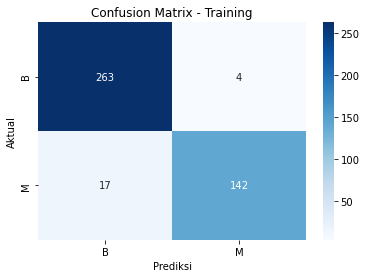

In [12]:
# Fitrya Irfan_202431073
# Langkah 12: evaluasi data latih
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Training")
cm_train = confusion_matrix(y_train, y_pred_train)
print(cm_train)
print(classification_report(y_train, y_pred_train, target_names=["B (Jinak)", "M (Ganas)"]))

sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues",
            xticklabels=["B", "M"], yticklabels=["B", "M"])
plt.title("Confusion Matrix - Training")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()


## Langkah 13 - Evaluasi data uji

Evaluasi Testing
[[86  4]
 [ 5 48]]
              precision    recall  f1-score   support

   B (Jinak)       0.95      0.96      0.95        90
   M (Ganas)       0.92      0.91      0.91        53

    accuracy                           0.94       143
   macro avg       0.93      0.93      0.93       143
weighted avg       0.94      0.94      0.94       143



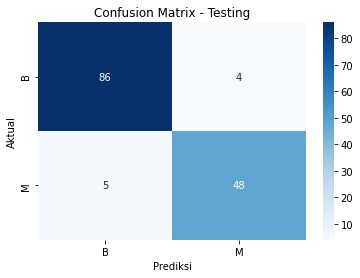

In [13]:
# Fitrya Irfan_202431073
# Langkah 13: evaluasi data uji
print("Evaluasi Testing")
cm_test = confusion_matrix(y_test, y_pred_test)
print(cm_test)
print(classification_report(y_test, y_pred_test, target_names=["B (Jinak)", "M (Ganas)"]))

sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=["B", "M"], yticklabels=["B", "M"])
plt.title("Confusion Matrix - Testing")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()


## Langkah 14 - Uji dengan 1 data baru

In [14]:
# Fitrya Irfan_202431073
# Langkah 14: uji dengan 1 data baru (urutan nilai mengikuti kolom x)
data_baru = pd.DataFrame([[13.37, 18.84, 86.24, 
                           551.1, 0.0959, 0.0926, 
                           0.0615, 0.0335, 0.1792, 
                           0.0615, 0.3242, 1.108, 
                           2.287, 24.53, 0.0064, 
                           0.0204, 0.0259, 0.0109, 
                           0.0187, 0.0032, 14.97, 
                           25.41, 97.66, 686.5, 
                           0.1313, 0.2119, 0.2267, 
                           0.0999, 0.2822, 0.08]], columns=x.columns)
hasil = model.predict(data_baru)[0]
print("Hasil prediksi (angka):", hasil)
print("Hasil prediksi (diagnosis):", "M (Ganas)" if hasil == 1 else "B (Jinak)")


Hasil prediksi (angka): 0
Hasil prediksi (diagnosis): B (Jinak)
